## Assignment 09: Cellular Networks and Satellites


<div class="alert alert-light">

  **Name:** Suleman Ali Khan
  
  **Matriculation Number:** 21-715-917
  
</div>



The submission deadline is <span style="background-color:rgba(0, 150, 255, 0.5); padding:2px 4px; border-radius:3px;">Monday, 2026-Nov-23 (23:59)</span>.
Students <span style="background-color:rgba(255, 123, 0, 0.5); padding:2px 4px; border-radius:3px;">must work alone</span> and provide their own results. 

Fill in your responses below in the marked blocks. The expected length of each answer is provided in each block.

- (S) Short, 1–2 sentences (~20–40 words). *A quick factual or definition-style answer.*
- (M) Medium, 3–8 sentences (~60–120 words). *Brief explanation with reasoning or an example.*
- (L) Long, multi-paragraph (150–300 words). *Detailed discussion, include reasoning, examples, and context.*
- (V) Visualizations and graphs. *Include plots or figures that illustrate your results.*
- (E) Statistical evaluation and information. *Provide numeric context such as mean, variance, random seed used, confidence intervals, etc.*

Save this notebook and upload the modified file to Moodle.

The motivation for this assignment is to understand how cellular networks and satellites reach their users: what limits the size and the capacity of a cell, how a network is planned for a real city, how a GNSS receiver finds a signal far below the noise, and where satellites serve better than masts. The cellular part starts with a few measurements with your own phone.

---

## Questions



### Step 1: Measure Your Cellular Network (1 point)

1) Open [`Network_Cellular_Measuring.ipynb`](../../notebooks/04%20Wireless%20Protocols/Network_Cellular_Measuring.ipynb). It shows how to read the network values on your phone and what to measure for this assignment. Measure your operator's network at three public places on the same day:
   * outdoors, on a square or a street;
   * inside a public building, near its entrance or a window;
   * deep inside: an underground station, a public garage, or the middle of a large building.

   At each place, note the network icon and the band, PCI and RSRP of the LTE serving cell, and run one speed test. Provide a table or cropped screenshots, and name your phone, your operator and the tool you used.

<div class="alert alert-info">

(V, S) Answer: Unfortunately was not able to do this Step of the exercise, but tried to complete whatever else I could in the assignment

2) Compute the building entry loss from your outdoor and indoor readings on the same PCI. Did the band change deeper inside? Explain why.

<div class="alert alert-info">

(M) Answer:

The customer is at 60 subscribers/km², just below the one-dish-beam capacity threshold of about 63 subscribers/km², but far above the direct-to-phone threshold of 0.14 subscribers/km² in the figure. The model estimates 27.6 km radio horizon for one 30 m mast, and for the 1 km² hut area `masts_needed` gives at least 1 mast.

I recommend low Earth orbit with a rooftop dish. It meets the 50 Mb/s demand because a dish beam provides 1,500 Mb/s across 119 km², while the hut requires only about 12 Mb/s (60 subscribers × 0.2 Mb/s). It also provides low one-way delay (1.6–4.3 ms for the qualifying LEO systems) and has no long coverage gaps. GEO would require no constellation handovers and provides continuous coverage, but its 126.9 ms one-way delay is unsuitable for the more interactive user experience and dish beam capacity is less flexible. A 30 m mast is the cheapest coverage option for the 1 km² hut, but the model's horizon and the remote mountainous setting make backhaul and terrain visibility uncertain; adding a mast is not a reason to rule out an LEO service. The dish and satellite constellation are the more reliable end-to-end connectivity choice.

### Step 2: Plan a Cellular Network (4 points)

1) Open [`Network_Cellular.ipynb`](../../notebooks/04%20Wireless%20Protocols/Network_Cellular.ipynb) and enter your matriculation number. Compute the link budget for 700 MHz, and for 3.5 GHz with and without beamforming. Provide the table. Which direction (downlink or uplink) limits the cell, and why? How does the model's building entry loss compare with the one you measured in Step 1?

<div class="alert alert-info">

(M) Answer: 

case                   beamforming   EIRP  NISV cut  MAPL DL  MAPL UL     limit   O2I  r outdoor  r indoor
700 MHz (n28, FDD)              no     61       0.0      163      154    uplink  17.7     4715 m    1657 m
3.5 GHz (n78, TDD)              no     61       0.0      153      148    uplink  26.8     1453 m     299 m
3.5 GHz (n78, TDD)             yes     71       0.0      163      153    uplink  26.8     1950 m     401 m
(EIRP in dBm; NISV cut: dB the downlink loses to the NISV cap; MAPL and O2I in dB)

The uplink limits all three cases because the phone's lower transmit power and antenna gain give it a smaller MAPL than the downlink. Beamforming raises the 3.5 GHz EIRP and both MAPLs, while leaving the model's 26.8 dB O2I loss unchanged. The model predicts 17.7 dB entry loss at 700 MHz and 26.8 dB at 3.5 GHz. 

2) Repeat the link budget with your distance to the nearest flat, `D_FLAT`. Provide the table. Does the NISV limit change the cell radius, without and with $K_{AA}$? If not, how close would the flat have to be?

<div class="alert alert-info">

(M) Answer:

Nearest flat: 23 m. NISV cap per band (two bands on one installation): 537 W ERP, with K_AA up to 5372 W in the beam

case                   beamforming   EIRP  NISV cut  MAPL DL  MAPL UL     limit   O2I  r outdoor  r indoor
700 MHz                         no     59       1.5      161      154    uplink  17.7     4715 m    1657 m
3.5 GHz without K_AA           yes     59      11.5      151      153  downlink  26.8     1780 m     366 m
3.5 GHz with K_AA              yes     69       1.5      161      153    uplink  26.8     1950 m     401 m
(EIRP in dBm; NISV cut: dB the downlink loses to the NISV cap; MAPL and O2I in dB)

At 23 m, the NISV limit does not change the 700 MHz radius: its downlink MAPL falls to 161 dB, which is still above the 154 dB uplink MAPL. It also does not change the 3.5 GHz radius with K_AA: the downlink remains above the 153 dB uplink MAPL, so the radius stays 1950 m outdoors and 401 m indoors. Without K_AA, however, the 11.5 dB cut reduces the 3.5 GHz downlink MAPL to 151 dB and reduces the radius from 1950 m to 1780 m outdoors (401 m to 366 m indoors). The NISV limit would have to reduce downlink below the uplink threshold: approximately 10 m for 700 MHz, 7 m without K_AA, and 9 m with K_AA.

3) Plot the median SINR against the site spacing, at full power and at one tenth of the power. Provide the plot. Where do the two curves meet? Why does more power stop helping in a dense network?

<div class="alert alert-info">

(V, M) Answer: 

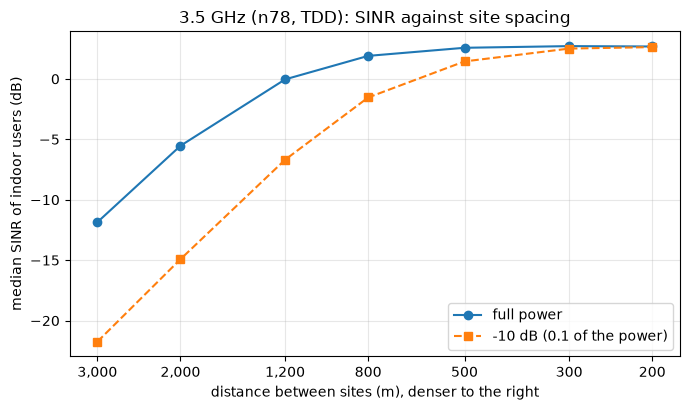

The curves converge at very dense site spacing, around 200 m; they are close at 300 m already and nearly coincide by 200 m (about 2.7 dB for full power and 2.6 dB for the reduced-power case). In the sparse, 3000-1200 m range, reducing transmit power lowers median SINR substantially because noise and weak neighbouring signals are relatively more important. In a dense network, stronger transmit power raises the desired signal and the interfering signals from neighbouring sites in roughly the same proportion. The SINR therefore becomes interference-limited, and a 10 dB power reduction has little effect on median SINR.

4) Compare reuse 1 and reuse 3 at a site spacing of 500 m, and provide the plot. Why do LTE and 5G use reuse 1, although reuse 3 gives a better SINR? Then walk a few hundred metres from your outdoor spot of Step 1 until the PCI changes. Provide both readings. Does your walk show reuse 1?

<div class="alert alert-info">

(V, M) Answer: 

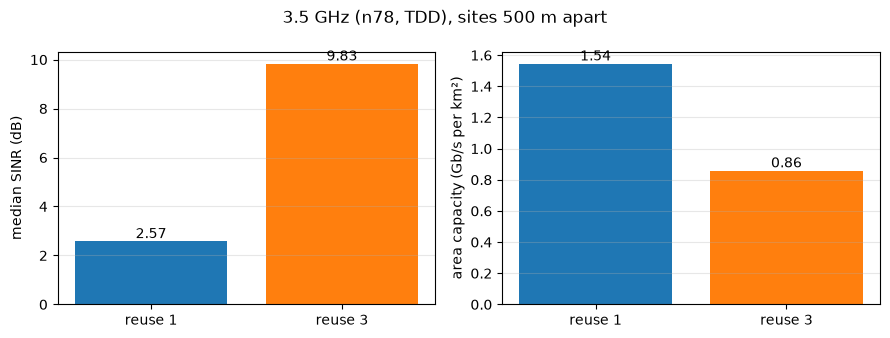

At 500 m site spacing, reuse 1 gives median SINR 2.57 dB and area capacity 1.54 Gb/s/km². Reuse 3 gives median SINR 9.83 dB but area capacity 0.86 Gb/s/km², because the frequency band is divided among three colour groups. LTE and 5G therefore generally use reuse 1: although reuse 3 lowers co-channel interference and improves SINR, reuse 1 gives each cell access to the entire bandwidth, which produces substantially higher area capacity. Adaptive scheduling and interference coordination manage the remaining interference.

5) Plot the knee for your district. Provide the plot. At which density of subscribers does each band turn from coverage-limited to capacity-limited? Is your district coverage- or capacity-limited in each band?

<div class="alert alert-info">

(V, M) Answer:

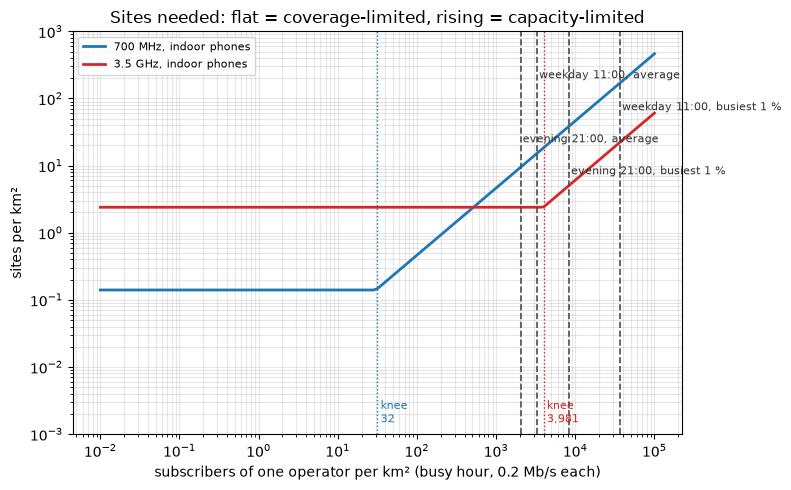

The knee occurs at about 32 subscribers/km² for 700 MHz and 3,981 subscribers/km² for 3.5 GHz. Below each knee, the required site density is flat because indoor coverage determines the network; above it, the site density rises with subscriber demand because capacity becomes limiting.

The Zurich densities plotted are 3,325/km² at weekday 11:00 average, 37,066/km² at weekday 11:00 busiest 1%, 2,061/km² at evening 21:00 average, and 8,431/km² at evening 21:00 busiest 1%. At 700 MHz, every plotted district density is above 32/km², so the district is capacity-limited. At 3.5 GHz, the two average scenarios are below the 3,981/km² knee and are coverage-limited, while the weekday and evening busiest-1% scenarios are above it and are capacity-limited.

6) Plan a network on your district's board. Make four designs and keep the plan string of each: two of your own, by clicking sites on the board, and two with `auto_plan` at different budgets. Plot them with `plot_designs`. Provide the plot and the plan strings.

<div class="alert alert-info">

(V) Answer: 

{"matriculation": "21-715-917", "district": "Zurich", "hour": "evening", "limits": "nisv", "plan": [6, 30, 35, 48, 56, 60, 63, 82, 96, 101, 111, 161, 166, 185, 197, 234]}
Zurich, evening 21:00, NISV, worst case (before 2021): 16 sites, CHF 3.92 M, demand served 33.8 %, people covered 99.8 %
   demand that is capacity-limited 79.2 %, interference-limited 0.2 %, coverage-limited 0.0 %

{"matriculation": "21-715-917", "district": "Zurich", "hour": "evening", "limits": "nisv", "plan": [6, 8, 15, 23, 29, 30, 33, 35, 48, 56, 60, 63, 66, 82, 96, 101, 111, 112, 117, 118, 123, 127, 161, 165, 166, 167, 175, 185, 197, 234]}
Zurich, evening 21:00, NISV, worst case (before 2021): 30 sites, CHF 7.92 M, demand served 61.9 %, people covered 99.6 %
   demand that is capacity-limited 50.6 %, interference-limited 0.4 %, coverage-limited 0.0 %


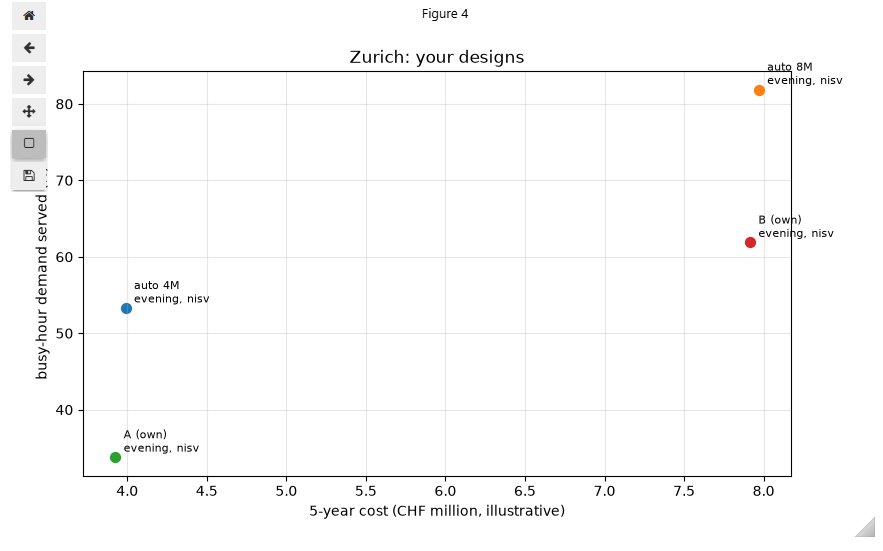





7) Which of your designs are dominated (another design serves at least as much for less money)? Which form the best trade-off?

<div class="alert alert-info">

(M) Answer:

A (own) is dominated: it costs CHF 3.92 M and serves 33.8% of demand, but auto 4M serves 53.3% for only CHF 3.99 M. B (own) is also dominated: it costs CHF 7.92 M and serves 61.9%, while auto 8M costs CHF 7.97 M and serves 81.9%. The Pareto front consists of auto 4M and auto 8M: neither is dominated because 4M gives much more demand per franc, whereas 8M gives the greatest absolute coverage.

For the best trade-off, auto 4M is the stronger choice: its 53.3% served demand costs 3.99 M, giving roughly 13.4 percentage points of demand served per million CHF. Auto 8M adds about 28.6 percentage points for 3.98 M more, so it is preferable only if the extra demand coverage is worth the substantially higher budget.

8) Recommend one plan for your district and give its plan string. Where is it coverage-, interference- or capacity-limited? Support the capacity argument with two speed tests at the same public place, one at a busy and one at a quiet time.

<div class="alert alert-info">

(E, M) Answer:

I recommend the 8M automatic plan. Its plan string is `{"matriculation":"21-715-917","district":"Zurich","hour":"evening","limits":"nisv","plan":[1,3,5,6,9,15,20,21,27,28,31,32,35,36,41,42,45,66,68,71,73,84,86,90,94,95,99,102,113,123,127,147,167,186,195,232,249]}`. With 37 sites and CHF 7.97 M, it serves 81.9% of demand and 99.8% of people; 30.4% of demand is capacity-limited, 0.2% interference-limited, and none is coverage-limited.



9) For your recommended plan, switch the hour and the limits on the board. How much of the demand is served on a weekday and in the evening, with and without $K_{AA}$? What does the NISV cost you?

<div class="alert alert-info">

(E, M) Answer:

For the recommended 37-site plan, switching the hour and NISV rule gives:

| Scenario | Demand served | Capacity-limited demand | Interference-limited demand |
|---|---:|---:|---:|
| Weekday 11:00, NISV without K_AA | 52.6% | 73.2% | 0.8% |
| Weekday 11:00, NISV with K_AA | 56.3% | 69.0% | 0.1% |
| Evening 21:00, NISV without K_AA | 81.9% | 30.4% | 0.2% |
| Evening 21:00, NISV with K_AA | 86.9% | 22.2% | 0.1% |

The weekday case has much greater demand and is consequently harder to serve. Without K_AA, NISV reduces weekday demand served from 56.3% to 52.6%, a 3.7 percentage-point cost, and evening demand from 86.9% to 81.9%, a 5.0 percentage-point cost. Thus K_AA materially improves both hours by allowing the 3.5 GHz beam to radiate more strongly while retaining its 6-minute averaging rule. Coverage-limited demand is 0% in all four cases.

10) Open [map.geo.admin.ch with the OFCOM layer of mobile antenna sites](https://map.geo.admin.ch/?layers=ch.bakom.standorte-mobilfunkanlagen). Find the site nearest to your outdoor spot of Step 1 and compare its distance with the distance your outdoor RSRP implies. Then show the real installations on the board. Explain if and why the real network is denser than your plan.

<div class="alert alert-info">

(M) Answer:

PRN 1: peak at code phase 2654 samples
   = 663.50 µs = 678.76 chips (true: 678.79 chips)
   = 198.91 km of range, modulo 299.8 km

The GPS C/A code is 1023 chips long and repeats every millisecond, so correlation identifies a delay only within one code period. One chip is about 977.5 ns, and 299.8 km is the light distance travelled in 1 ms. A receiver determines the correct whole-code-period number from knowledge of GPS time and the satellite transmit time carried in the navigation message, together with decoded ephemeris and an approximate receiver position/time. Combining pseudoranges from several satellites by least-squares or joint state estimation removes the receiver clock offset and resolves the absolute ranges used for a 3-D position fix.

### Step 3: Satellite Navigation (2 points)

1) Open [`Network_GNSS.ipynb`](../../notebooks/04%20Wireless%20Protocols/Network_GNSS.ipynb) and enter your matriculation number. Report your PRN and your code phase in samples, chips, microseconds and kilometres. Why is the distance only known modulo about 300 km? How does a receiver find the rest?

<div class="alert alert-info">

(M) Answer: 

PRN 1: peak at code phase 2654 samples
   = 663.50 µs = 678.76 chips (true: 678.79 chips)
   = 198.91 km of range, modulo 299.8 km

The GPS C/A code is 1023 chips long and repeats every millisecond, so correlation identifies a delay only within one code period. One chip is about 977.5 ns, and 299.8 km is the light distance travelled in 1 ms. A receiver determines the correct whole-code-period number from knowledge of GPS time and the satellite transmit time carried in the navigation message, together with decoded ephemeris and an approximate receiver position/time. Combining pseudoranges from several satellites by least-squares or joint state estimation removes the receiver clock offset and resolves the absolute ranges used for a 3-D position fix.

2) Provide the acquisition plot for 1 ms and 10 ms. Why does GPS work outdoors at about 45 dB-Hz, but struggle indoors at 25 dB-Hz?

<div class="alert alert-info">

(V, M) Answer:

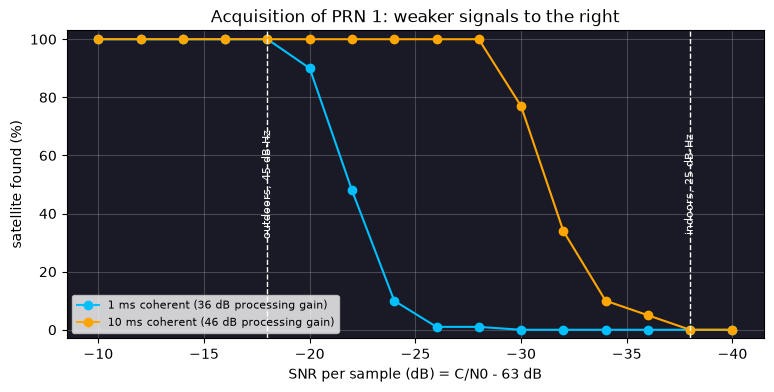

The 1 ms coherent acquisition search succeeds in at least 90% of trials down to about -20 dB SNR per sample, while the 10 ms search reaches about -28 dB. Thus coherent integration over ten code periods gives a 10 dB improvement in the model, although it can also expose the same navigation-message and frequency-search limits.

At 45 dB-Hz outdoors, the receiver has enough carrier-to-noise density to form a strong correlation peak with only 1 ms of integration. At 25 dB-Hz indoors, building and other losses reduce C/N0 by 20 dB; the SNR per sample is correspondingly much weaker, and indoor attenuation, noise, multipath and motion make the peak unreliable. The 10 ms search has a better chance than 1 ms, but it may still not reach the acquisition threshold.

3) Pick a narrow street you know and a time, and enter its place, width, wall height and direction. Provide the sky plot, the table and the street sweep. How many satellites does the model expect in your street, with GPS and Galileo only and with all four systems (GPS, Galileo, GLONASS and BeiDou)? Why do phones use all four?

<div class="alert alert-info">

(V, M) Answer:

I used Thesenacher near Ankenbüel, Zumikon, at approximately 47.3273948° N, 8.6310143° E. The model was run for 2026-11-18 15:25 Swiss local time, with a 12 m street width, 15 m walls and a street direction of 281° (the west-northwest/east-southeast orientation of the road).

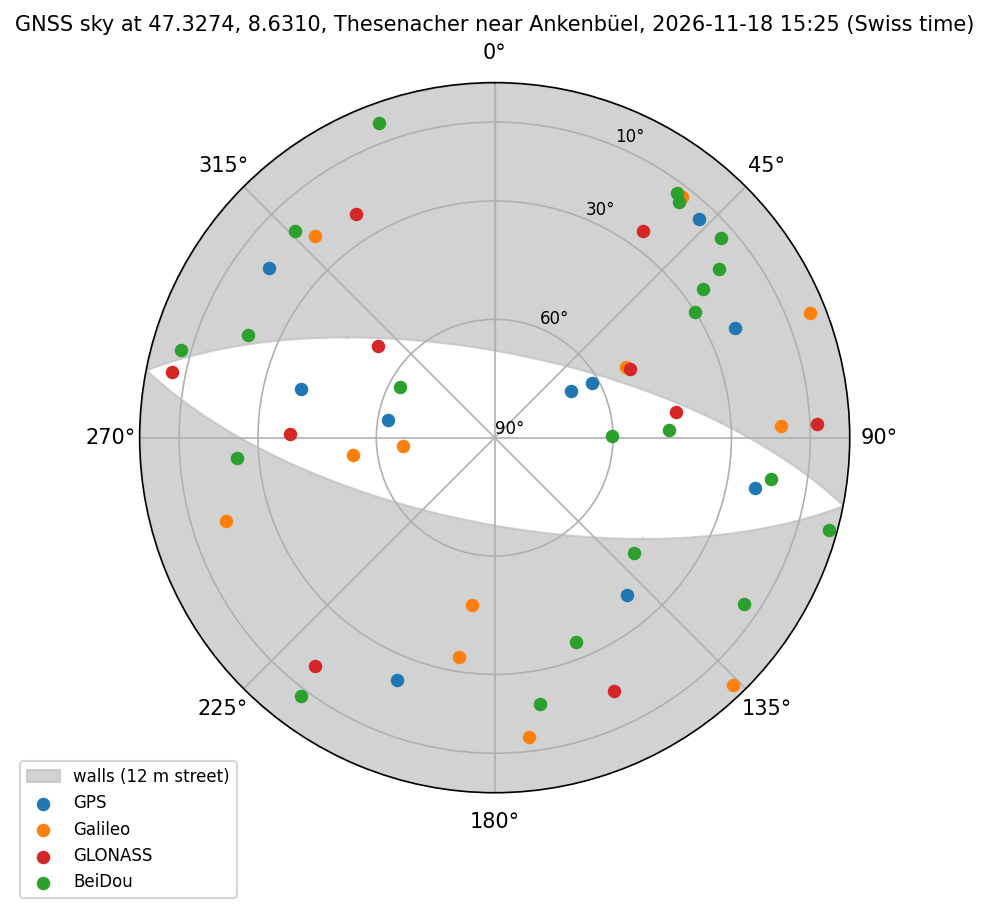

| Case | GPS + Galileo | All four systems |
|---|---:|---:|
| Open sky: satellites | 20 | 45 |
| Open sky: PDOP / HDOP | 1.1 / 0.6 | 0.8 / 0.4 |
| Open sky: estimated accuracy | 1.7 m | 1.1 m |
| Street 12 m wide, 15 m walls: satellites | 7 | 14 |
| Street: PDOP / HDOP | 4.0 / 3.1 | 2.9 / 2.2 |
| Street: estimated accuracy | 9.3 m | 6.6 m |

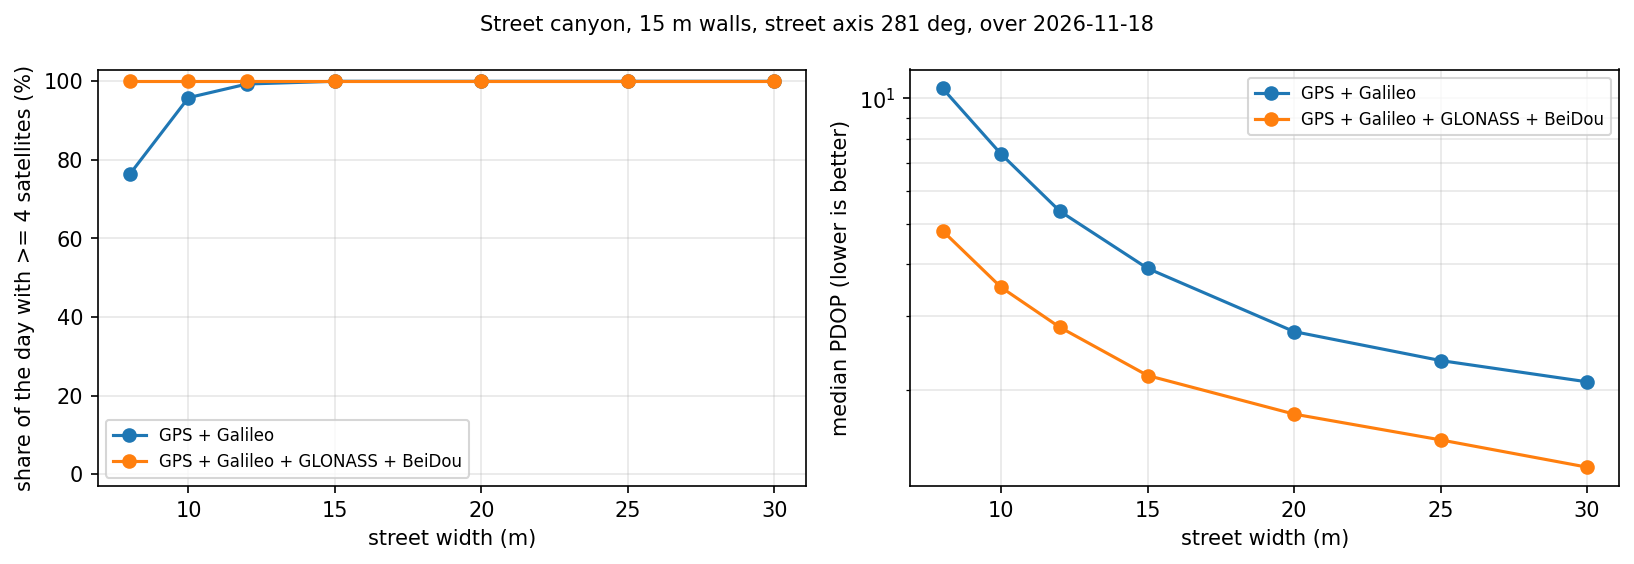

In the street sweep with 15 m walls, the 12 m case gives a 99% fix share with median PDOP 5.4 for GPS+Galileo, versus 100% with PDOP 2.8 for all four systems. Phones use all four constellations because it increases the number of usable satellites and spreads them across more directions, improving geometry and reducing PDOP. The additional systems are also valuable because one constellation may be temporarily blocked or poorly distributed, and extra satellites provide redundancy and faster re-acquisition.

4) A real phone in a narrow street is often less accurate than this model predicts. What does the model leave out?

<div class="alert alert-info">

(M) Answer:

The model assumes a perfectly straight canyon with identical 12 m spacing and uniform 15 m walls. It leaves out balconies, overhangs, trees, parked vehicles, building openings and variations in wall height and spacing. It also treats every visible signal as ideal, using one fixed 3 m range error, while a real phone is affected by multipath, diffraction, attenuation, antenna orientation, vehicle motion and noise; reflected signals may appear farther away or at incorrect angles.

The snapshot is a simplified orbital calculation rather than real-time corrections, and the model does not include ionospheric/tropospheric delays, ephemeris or clock errors, carrier-phase ambiguity, receiver filtering, or inter-system biases. It assumes simultaneous visibility at every satellite and ignores sudden occlusion and weak-signal reacquisition. A phone therefore combines GNSS with Wi-Fi, cellular, barometric pressure and inertial sensors and can still estimate a plausible position despite a poor street-sky geometry.

### Step 4: Satellite Communication (2 points)

1) Open [`Network_Satellite_Planning.ipynb`](../../notebooks/04%20Wireless%20Protocols/Network_Satellite_Planning.ipynb) and enter your matriculation number. The notebook gives you a customer far away from any mast, for example a research ship near Svalbard. Compare how the real satellite systems serve your customer over one simulated day. Provide the table and the plot. Which systems meet your customer's need, and why do the others not?

<div class="alert alert-info">

(V, E, M) Answer:

Your customer: Alpine hut, Bernese Oberland (46.5° N, 8.0° E)
Need: guest Wi-Fi and a webcam, about 50 Mb/s total; rooftop dish acceptable; gaps must remain under 5 minutes.
Assumed customer density: 60 subscribers, approximately 60 per km²; sky hidden below 20° elevation.

| System | Satellites | Mask | Available | Longest gap | Satellites in view | Best elevation | One-way delay | Doppler at 2 GHz |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Starlink 53° | 4977 | 25° | 100.0% | 0 min | 46 | 74.9° | 1.6 ms | 42.4 kHz |
| Starlink 43° | 3613 | 25° | 100.0% | 0 min | 20 | 48.2° | 2.1 ms | 36.6 kHz |
| Starlink 70° | 708 | 25° | 99.4% | 2 min | 4 | 50.9° | 2.3 ms | 41.9 kHz |
| Starlink 97.6° | 1354 | 25° | 93.7% | 21 min | 3 | 53.8° | 1.9 ms | 43.8 kHz |
| OneWeb | 651 | 25° | 100.0% | 0 min | 11 | 68.8° | 4.3 ms | 40.4 kHz |
| Iridium | 80 | 20° | 80.5% | 4 min | 1 | 31.6° | 4.4 ms | 41.7 kHz |
| GEO | 368 | 20° | 100.0% | 0 min | 104 | 36.6° | 126.9 ms | 0.0 kHz |

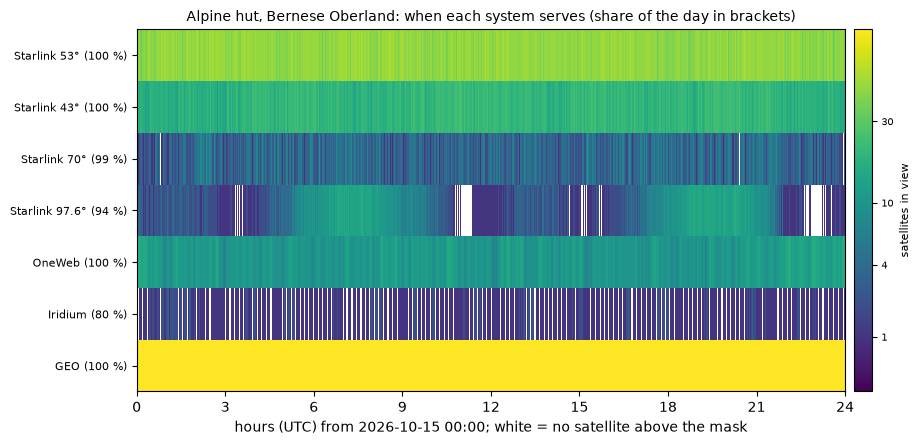

The systems meeting the availability and gap requirements are both dense Starlink shells (53° and 43°), Starlink 70°, OneWeb and GEO. They provide at least 95% daily availability and no gap over 5 minutes. Starlink 97.6° reaches only 93.7% availability and has a 21-minute longest gap. Iridium has a 4-minute longest gap but only 80.5% availability and is unsuitable for the 50 Mb/s broadband requirement.

2) Compare the delay and the Doppler shift of the systems that meet the need. What do they mean for your customer?

<div class="alert alert-info">

(M) Answer:

Among the systems meeting the need, Starlink 53°, 43° and 70° have one-way delays of 1.6, 2.1 and 2.3 ms and Doppler shifts of 42.4, 36.6 and 41.9 kHz at 2 GHz. OneWeb has 4.3 ms delay and 40.4 kHz Doppler, while GEO has 126.9 ms one-way delay and negligible Doppler.

The LEO systems provide very low latency and are suitable for interactive guest Wi-Fi and a webcam, although the large Doppler and rapid satellite motion require tracking, handovers and frequency/timing correction. GEO makes the webcam and web traffic possible with a fixed rooftop dish and no Doppler problem, but its roughly 127 ms one-way delay is about 500 ms round-trip through the full satellite/gateway path. It is therefore slower for interactive applications such as voice or games; the LEO choices are preferable for low latency.

3) Design one what-if shell that covers your customer with as few satellites as you can. Report its altitude, inclination, planes, satellites per plane and results, next to the best real system. Are there any trade-offs?

<div class="alert alert-info">

(E, M) Answer:

The designed Walker shell has 7 planes with 14 satellites per plane: 98 satellites at 500 km altitude and 50° inclination. With the 25° dish mask, it provides 96.2% availability and a longest gap of 3 minutes, so it just meets the customer's 95% availability and 5-minute-gap requirements. It has a median of 1 satellite in view, 41.2° best elevation, 2.4 ms one-way delay and 40.8 kHz maximum Doppler at 2 GHz.

The best real system for availability is the 53° Starlink shell, with 4,977 satellites, 100% availability, no gap, a median of 46 satellites in view, 1.6 ms delay and 42.4 kHz Doppler. The what-if shell uses only 98 satellites but is much less robust: a single median satellite in view leaves little redundancy for handover or a failed satellite. Starlink provides better coverage margins and near-continuous diversity at the cost of a much larger constellation. The shell is thus a low-satellite coverage design, not evidence that it would provide comparable broadband capacity.

4) Draw the figure that compares masts and satellites for your customer (`bridge_figure`), and provide it. How many subscribers per km² can one dish beam and one direct-to-phone beam carry? Why does a constellation need thousands of satellites for capacity, but only hundreds for coverage?

<div class="alert alert-info">

(V, M) Answer:

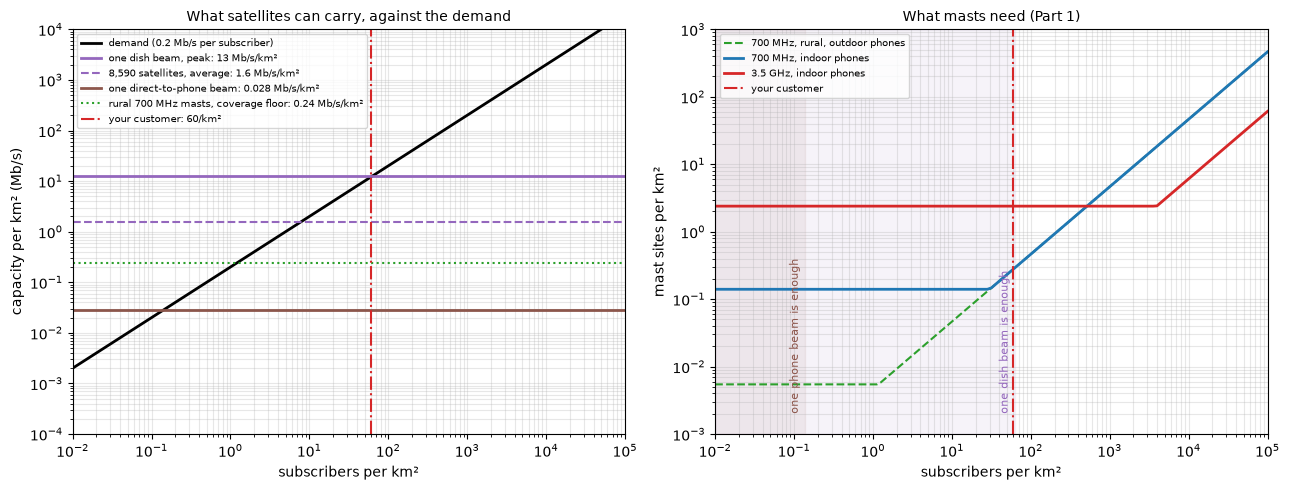

One dish beam covers about 119 km² and provides 1,500 Mb/s, or 12.66 Mb/s/km². At the model's busy-hour demand of 0.2 Mb/s per subscriber, it can serve about 63 subscribers/km². One direct-to-phone beam covers about 180 km² and provides 5 Mb/s, or 0.028 Mb/s/km², corresponding to about 0.14 subscribers/km². The customer is at 60 subscribers/km², so the dish beam is just large enough while a direct-to-phone beam is far below its required capacity density.

A constellation needs only hundreds of satellites for coverage because each satellite footprint reaches a large area and the goal is only to keep at least one beam above the elevation mask. Capacity requires thousands of satellites because a constellation must provide enough simultaneously visible satellites and reuse of many spot beams to carry the requested busy-hour traffic everywhere. Coverage depends on orbital geometry, whereas capacity depends on total throughput per area and demand; each satellite adds limited beam capacity, so many more satellites are needed as traffic density rises.

5) Where does your customer sit in the figure? How many 30 m masts would it need instead (`masts_needed`)? Decide between masts, low orbit and geostationary for your customer. Give at least three of your own numbers as reasons.

<div class="alert alert-info">

(M) Answer:

The customer is at 60 subscribers/km², just below the one-dish-beam capacity threshold of about 63 subscribers/km², but far above the direct-to-phone threshold of 0.14 subscribers/km² in the figure. The model estimates 27.6 km radio horizon for one 30 m mast, and for the 1 km² hut area `masts_needed` gives at least 1 mast.

I recommend low Earth orbit with a rooftop dish. It meets the 50 Mb/s demand because a dish beam provides 1,500 Mb/s across 119 km², while the hut requires only about 12 Mb/s (60 subscribers × 0.2 Mb/s). It also provides low one-way delay (1.6–4.3 ms for the qualifying LEO systems) and has no long coverage gaps. GEO would require no constellation handovers and provides continuous coverage, but its 126.9 ms one-way delay is unsuitable for the more interactive user experience and dish beam capacity is less flexible. A 30 m mast is the cheapest coverage option for the 1 km² hut, but the model's horizon and the remote mountainous setting make backhaul and terrain visibility uncertain; adding a mast is not a reason to rule out an LEO service. The dish and satellite constellation are the more reliable end-to-end connectivity choice.

### Optional Feedback (not graded)

1. Did you read through and understand all the tasks in this assignment and the related notebooks? Are there any shortcomings, missing parts, or sections that should be improved? You can also give your feedback anonymously, through moodle. Please help the teaching team by telling us what part was not understood, and we will work on it in the future.

<div class="alert alert-info">

Optional Feedback, not graded: *(double click to edit)*